## 비지도 학습 
정답(`y`) 없이 입력 데이터 (피처, `X`)의 구조와 패턴을 학습하는 방법

|구분| 지도학습 | 비지도학습 |
|---|---|---|
|**데이터**| 입력 + 정답 (`fit(X,y)`) | 입력만 (`fit(X)`) |
|**목표**| 정답 예측/분류 | 숨은 패턴/구조 발견 |
|**평가**| 정답과 비교 (정확도, f1 등) | 정량 지표(실루엣 등) + 도메인 해석 |

### 대표적인 유형
- **군집화(Clustering)** : 비슷한 특성의 데이터끼리 그룹화
- **차원축소(Dimensionality Reduction)**  : 많은 피처를 적은 수의 핵심 축으로 압축 -> 다중공선성 완화 및 시각화
- **이상 탐지(Anomaly Detection)** : 정상 범위에서 벗어난 패턴 감지 . 이상 거래 및 급변 탐지

> 거리, 분산 기반 알고리즘이 많으므로 **스케일링이 필수**이며,
> 군집의 의미는 최종적으로 **도메인 지식**으로 검증해야 함!

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from _style import setup
from _ml import load_merged, SEED

setup()
pd.set_option("display.width", 130)

print("준비 완료")

준비 완료


In [2]:
# 120개 종목을 수익률 패턴으로 군집화하고 실제 섹터와 비교

df = load_merged()

# 일간 수익률 피처 추가
df["ret"] = df.groupby("code")["close"].pct_change()

# 데이터를 (날짜 * 종목) 행렬로 만들기
#   행 = 날짜, 열 = 종목, 값 = 수익률

pivot = df.pivot_table(index="date", columns="code", values="ret")

# 종목별 섹터
sector = df[["code","sectorName"]].drop_duplicates().set_index("code")["sectorName"]
true_labels = sector[pivot.columns].values

print(f"수익률 행렬 : {pivot.shape} (날짜 x 종목)")
print(f"군집화 입력 : {pivot.T.shape} (종목 x 날짜)")
print()
print("종목을 묶을 것이므로 '종목이 행'이 되도록 전치(.T) 한다.")
print(f"각 종목이 {pivot.shape[0]}개의 값으로 표현된다. (날짜별 수익률)")
print()
print(f"섹터 {len(set(true_labels))}종류, 종목 ({len(true_labels)})개")
print(pd.DataFrame(true_labels).value_counts())

수익률 행렬 : (749, 120) (날짜 x 종목)
군집화 입력 : (120, 749) (종목 x 날짜)

종목을 묶을 것이므로 '종목이 행'이 되도록 전치(.T) 한다.
각 종목이 749개의 값으로 표현된다. (날짜별 수익률)

섹터 10종류, 종목 (120)개
0    
금융       18
전기전자     16
IT서비스    14
유통       12
화학       12
바이오      12
운수장비     12
건설       10
에너지       8
식품        6
Name: count, dtype: int64


---
### K-Means 군집화
k개의 평균을 찾는 알고리즘

1. k개의 중심점을 선정 (무작위)
2. 각 데이터를 가장 가까운 중심점에 배정
3. 각 그룹의 평균으로 중심점을 이동
4. 중심점이 움직이지 않을 때 까지 2, 3번 반복

In [3]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score, davies_bouldin_score

def clustering(matrix, k=10, scale=True):
    """ 군집화하여 결과를 반환 """

    M = matrix.T.values                      # 행 = 종목, 열 = 날짜

    if scale:
        M = StandardScaler().fit_transform(M)

    # km = KMeans(n_clusters=k)
    km = KMeans(
        n_clusters=k,
        random_state=SEED,      # 재현성
        n_init=10,              # n(10)번 시도해서 가장 좋은 결과를 고름
        )

    pred = km.fit_predict(M)                 # 학습 + 각 종목의 군집 번호

    return pred, M, km          # (예측결과, 입력데이터(X), 모델)

preds, M_scaled, km = clustering(pivot, k=10, scale=True)

print("군집별 종목 수 : ")
print(pd.Series(preds).value_counts().sort_index().to_string())

군집별 종목 수 : 
0     5
1    18
2    25
3    14
4     2
5    15
6    13
7     7
8    12
9     9


**`random_state`, `n_init` 을 둘 다 지정해야, 매번 실행했을때 동일한 결과를 확인할 수 있음(재현성)**
설정하지 않으면, 중심점을 무작위로 찍고 시작하기 때문에, 실행마다 다른 군집이 나올 수 있음.

- random_sate=42 : 랜덤 시드를 동일하게 주어, 항상 같은 곳을 찍게함.
- n_init=10 : 여러번 시도해서 가장 좋은 결과를 고름.

---



### 스케일링 처리 유/무 비교

In [5]:
lab_raw, M_raw, _ = clustering(pivot, k=10, scale=False)        # 스케일링 처리 x
lab_scaled, M_scaled, _ = clustering(pivot, k=10, scale=True)   # 스케일링 처리 o

vol = pivot.std()

rows = []

for name, lab in [("스케일링 X", lab_raw),("스케일링 O", lab_scaled)]:
    # 각 군집의 평균 변동성을 구해서 가장 높은 군집과 가장 낮은 군집의 차이
    vol_by_cluster = pd.Series(vol.values).groupby(lab).mean()

    rows.append({
        "방식": name,
        "섹터와 일치(ARI)" : adjusted_rand_score(true_labels, lab),
        "군집간 변동성 차이": vol_by_cluster.max() - vol_by_cluster.min()
    })
    # ARI : 두 그룹이 얼마나 일치하는가? 얼마나 비슷하게 잘 묶였는가?
    #   1.0 : 완전 일치 / 0.0 : 무작위와 같음 
    # * 정답이 없는 비지도학습이기 때문에 원래는 이 방식을 적용하기 어려우나,
    #   참고할 수 있는 데이터가 있으므로 비교가 가능 *

print(pd.DataFrame(rows).round(4).to_string(index=False))  

    방식  섹터와 일치(ARI)  군집간 변동성 차이
스케일링 X       0.0333      0.0035
스케일링 O       0.5265      0.0053


**스케일링 없는 경우(X)는 섹터 구분이 전혀 안됨! (ARI 0.033)**
K-Means는 거리로 판단하기 때문에, 모든 종목에 똑같이 더해지는 시장 흐름은 종목간 거리에서 상쇄될것임.\
대신, 변동이 큰 날의 값이 거리를 좌우하기 때문에 섹터 차이가 묻히는 것으로 보임.
하지만 스케일링 (StandardScaler)을 적용하면 ARI가 0.53까지 올라감!

**스케일링한 군집 결과를 섹터와 비교**

In [6]:
cross_table = pd.crosstab(pd.Series(lab_scaled, name="군집"),
                          pd.Series(true_labels, name="섹터"))
most = cross_table.max(axis=1).sum()

print(cross_table.to_string())
print()
print(f"군집 순도 : {most / cross_table.values.sum():.2f}")

섹터  IT서비스  건설  금융  바이오  식품  에너지  운수장비  유통  전기전자  화학
군집                                                 
0       0   0   0    2   0    0     2   0     0   1
1       0   1  16    0   1    0     0   0     0   0
2      14   0   0    1   0    0     5   1     3   1
3       0   9   1    0   0    0     2   1     0   1
4       0   0   0    0   1    1     0   0     0   0
5       0   0   0    2   0    0     1   0    12   0
6       0   0   0    0   1    0     1  10     1   0
7       0   0   0    7   0    0     0   0     0   0
8       0   0   1    0   3    7     1   0     0   0
9       0   0   0    0   0    0     0   0     0   9

군집 순도 : 0.72


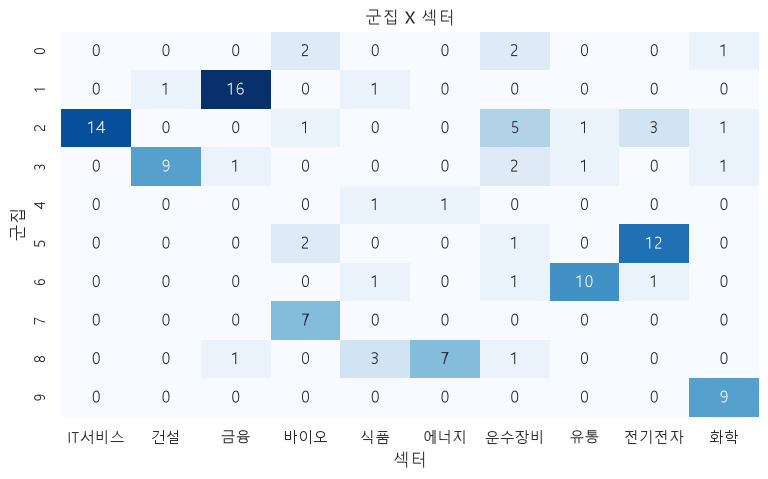

In [8]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(9, 5))

sns.heatmap(cross_table, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("군집 X 섹터")

plt.show()

**군집 결과 (k=10, 스케일링적용)**
- 순도 0.72 : 각 군집에서 가장 많은 섹터의 종목 수를 모두 더해 전체 종목 수(120)로 나눈 값. 1.0이면 군집과 섹터가 일치.
- 잘 묶여진 섹터 : IT 서비스(14/14), 금융(16/18), 건설(9/10), 유통(10/12), 화학(9/12), 전기전자(12/16)
- 섞인 것 : 운수장비(12)는 어느 군집도 주도하지 못하고 흩어짐(최대 5). 군집 8  에너지(7), 식품(3)가 섞임. 군집0번, 4번은 작게 섞여있는 군집.
- 순도는 군집 수가 많을 수록 높아지기 쉬운 지표임. (K=종목수 -> 1.0). 그렇기 때문에 ARI(0.53)와 같이 분석해야 함. 
- 같은 섹터 종목이 비슷하게 움직인다는 가정은 대체로 맞음. 다만, 운수장비처럼 수익률 패턴이 섹터 안에서 제각각인 경우는 수익률만으로는 구분이 어려움.
---

### k를 정하는 방법 

|방법|보는 관점|방향|
|---|---|---|
|엘보| K를 늘릴수록 오차가 줄어듦, 꺾이는 지점 | - |
|실루엣 계수| 군집 안은 뭉치고, 군집 간은 떨어졌는가? | 높을 수록 좋음 |
|DBI| 군집끼리 잘 분리 되었는가? | 낮을 수록 좋음 |

In [11]:
ks = range(2, 16)
rows = []

for k in ks:
    # k값을 변경하면서 KMeans 모델 생성 -> 군집화
    km_k = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(M_scaled)

    lab_k = km_k.labels_

    rows.append({
        "k": k,
        "관성": km_k.inertia_,      # 엘보 확인용. 낮을수록 좋음
        "실루엣": silhouette_score(M_scaled, lab_k),  # 높을수록 좋음. 군집간 분리도와 내부 응집도 종합.
        "DBI": davies_bouldin_score(M_scaled,lab_k),  # 낮을수록 좋음.
        "ARI": adjusted_rand_score(true_labels, lab_k)
    })

k_table = pd.DataFrame(rows) 

print(k_table.round(4).to_string(index=False))

 k         관성    실루엣    DBI    ARI
 2 86829.6581 0.0249 5.3262 0.1593
 3 85487.7156 0.0163 5.0055 0.2217
 4 84580.5442 0.0139 5.1342 0.2523
 5 83066.5696 0.0134 4.7518 0.2501
 6 82233.8038 0.0084 4.6291 0.2950
 7 80815.0873 0.0141 4.5523 0.4656
 8 80265.0721 0.0089 4.4493 0.4634
 9 79205.4191 0.0027 3.7824 0.4252
10 77600.6181 0.0147 3.7209 0.5265
11 77306.6468 0.0075 3.7116 0.4172
12 76122.9891 0.0047 3.6581 0.4532
13 74993.5229 0.0154 3.3516 0.5808
14 74657.9752 0.0018 3.5112 0.3796
15 73741.1954 0.0054 3.0951 0.5034


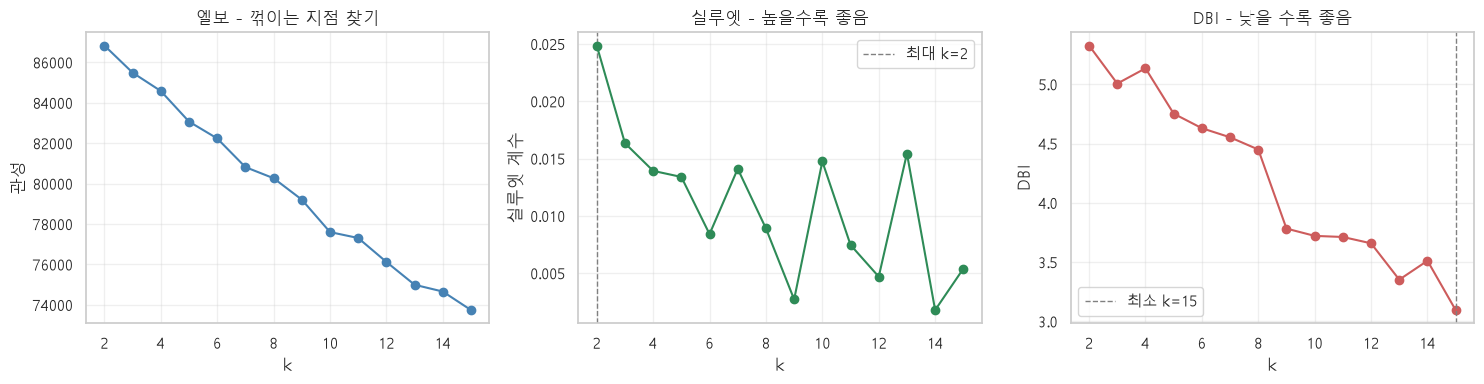

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 엘보
axes[0].plot(k_table["k"], k_table["관성"], "o-", color="steelblue")

axes[0].set_xlabel("k")
axes[0].set_ylabel("관성")
axes[0].set_title("엘보 - 꺾이는 지점 찾기")
axes[0].grid(alpha=0.3)

# 실루엣
best_sil = k_table.loc[k_table["실루엣"].idxmax(), "k"]

axes[1].axvline(best_sil, color="gray", ls="--", lw=1, label=f"최대 k={best_sil}")
axes[1].plot(k_table["k"], k_table["실루엣"], "o-", color="seagreen")

axes[1].set_xlabel("k")
axes[1].set_ylabel("실루엣 계수")
axes[1].set_title("실루엣 - 높을수록 좋음")
axes[1].legend()
axes[1].grid(alpha=0.3)

# DBI
axes[2].plot(k_table["k"], k_table["DBI"],"o-",color="indianred")
best_dbi = k_table.loc[k_table["DBI"].idxmin(), "k"]
axes[2].axvline(best_dbi, color="gray",ls="--",lw=1, label=f"최소 k={best_dbi}")

axes[2].set_xlabel("k")
axes[2].set_ylabel("DBI")
axes[2].set_title("DBI - 낮을 수록 좋음")
axes[2].legend()
axes[2].grid(alpha=0.3)

fig.tight_layout()
plt.show()

**1. 엘보가 뚜렷하지 않음**
> 관성곡선이 완만하게 내려가기만 해서 어디가 팔꿈치 지점인지 알 수 없음. -> 일반적인 현상

**2. 실루엣이 매우 낮음 (0.02 수준)**
> 군집이 뚜렷하게 나뉘지 않음. -> 금융 수익률 데이터에서는 일반적임.

**3. 모든 지표가 다른 K가 좋다고 함**
> 실루엣이 작은 K, DBI가 큰 K가 각각 있음. 어느 하나를 기계적으로 믿으면 안됨!\
> 결국, 도메인 지식이 필요함. -> 섹터가 10개이므로, K=10